# Datenvisualisierung mit Python

## Visualisierungstechniken

aufgeschlüsselt nach den zugrundeliegenden **Daten (WAS)** und **Zielen (WARUM)**:

https://www.data-to-viz.com

https://python-graph-gallery.com

## Visualisierungsbibliotheken

Beispiele:
* Matplotlib (https://matplotlib.org/gallery/index.html#)
* Pandas Visualization (https://pandas.pydata.org/pandas-docs/stable/user_guide/visualization.html)
* Seaborn (https://seaborn.pydata.org)
* Plotly (https://plotly.com/python/)
* Altair (https://altair-viz.github.io/gallery/simple_line_chart.html)
* Bokeh (https://docs.bokeh.org/en/latest/index.html)

https://towardsdatascience.com/top-6-python-libraries-for-visualization-which-one-to-use-fe43381cd658

## Statistische Datenvisualsierung mit Seaborn

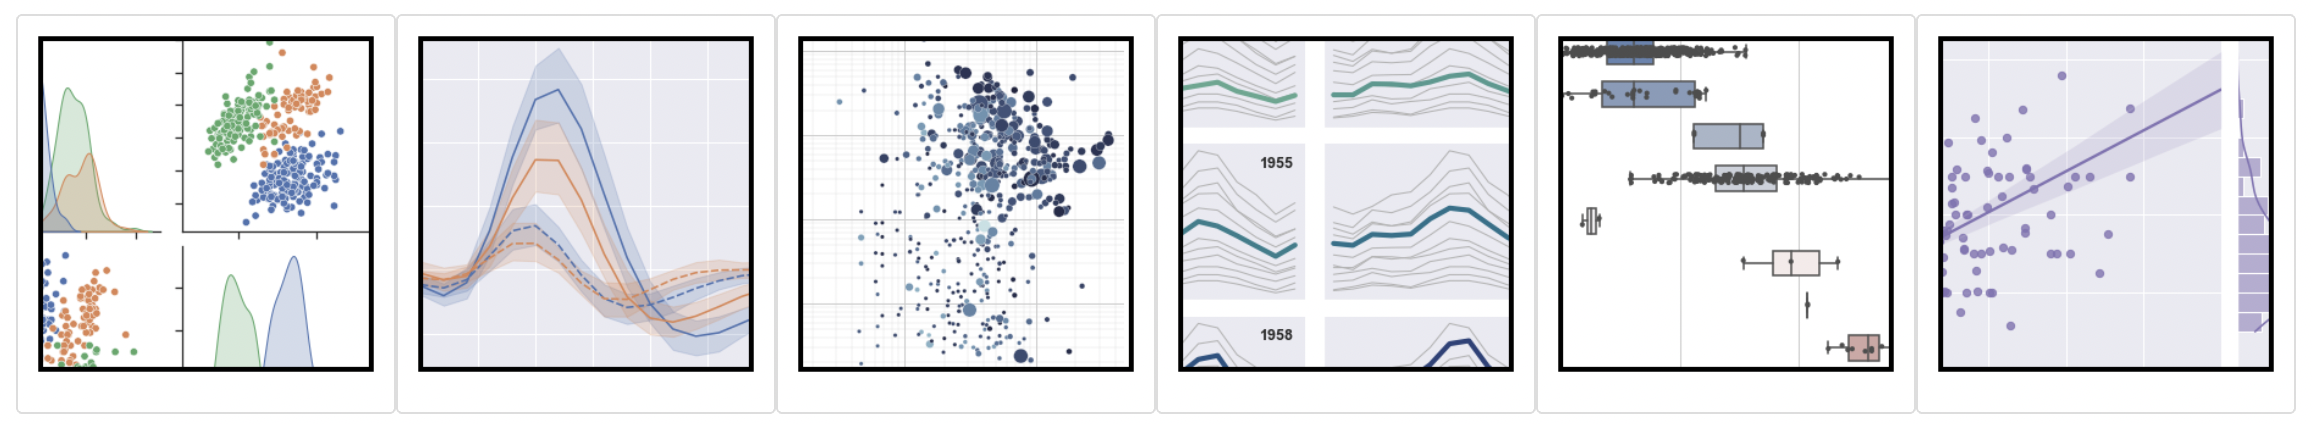

Seaborn ist eine statistische Plotting Bibliothek um Diagramme darzustellen und harmoniert sehr gut mit den Pandas Dataframe-Objekten.

## Links:
* Website: https://seaborn.pydata.org
* Beispiele: https://seaborn.pydata.org/examples/index.html
* API: https://seaborn.pydata.org/api.html

## Installation
`conda install seaborn` oder `pip install seaborn`

## Import

In [1]:
#!pip install seaborn

In [2]:
import seaborn as sns

## Daten

Seaborn verfügt über eingebaute Datensets, die man nutzen kann, z.B. den "Tips"-Datensatz, der Daten zum Trinkgeld in einem Restaurant beschreibt. Man kann jedoch auch wie gewohnt CVS Dateien laden und das DataFrame übergeben.

In [3]:
# verfügbare Datensätze:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [4]:
tips = sns.load_dataset("tips")

In [5]:
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


## Barcharts

Barcharts aggregieren quantitative Werte verschiedener Kategorien und erlauben deren Vergleich über die Länge der Balken.

**WARUM:** Werte vergleichen und identifzieren

**WAS:** ein nominales/ordinales + ein quantitatives Attribut

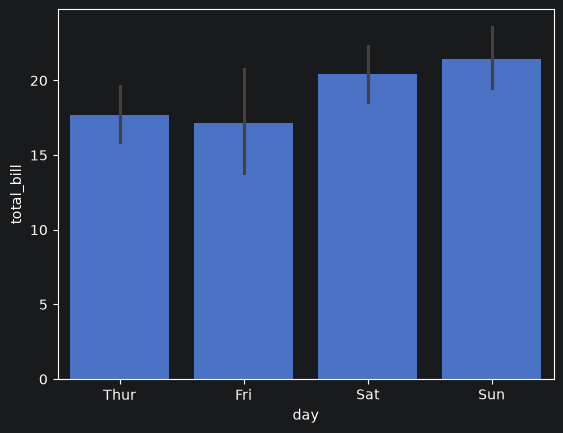

In [6]:
sns.barplot(x="day", y="total_bill", data=tips);

Änderung des Fehlerbalkens über estimator (z.B. np.std, median)

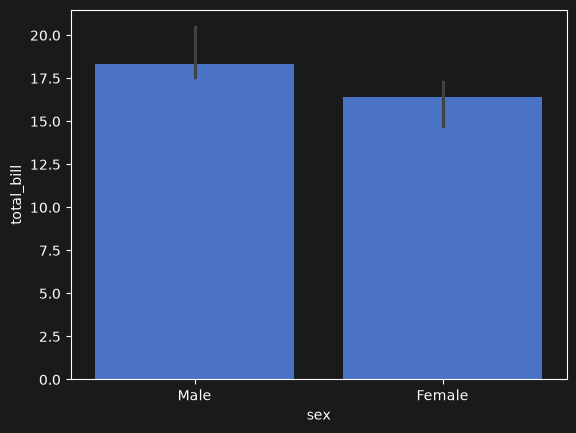

In [7]:
import numpy as np
from numpy import median
sns.barplot(x="sex", y="total_bill", data =tips, estimator = median); #estimator = np.std | median

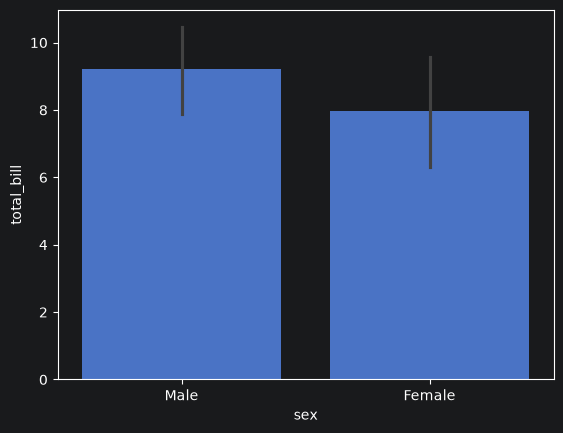

In [8]:
import numpy as np
from numpy import median
sns.barplot(x="sex", y="total_bill", data =tips, estimator = np.std); #estimator = np.std | median

x und y können vertauscht werden für einen horizontalen Bar Chart. Besser geeignet bei langen Achsenbeschriftungen, da Lesbarkeit verbessert wird. Weiterhin können Unterkategorien verglichen werden, z.B. getrennt durch Farbe:

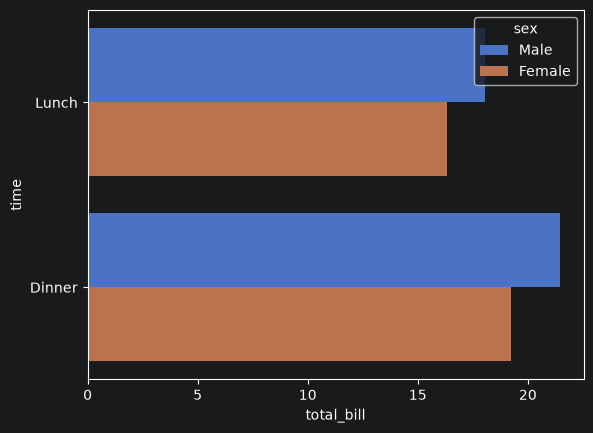

In [9]:
sns.barplot(x="total_bill", y="time", hue="sex", data=tips, errorbar=None); # None entfernt den Fehlerbalken

`Countplot` kann verwendet werden, um stattdessen die Anzahl der Einträge für eine bestimmte Kategorie zu zählen:

<Axes: xlabel='count', ylabel='sex'>

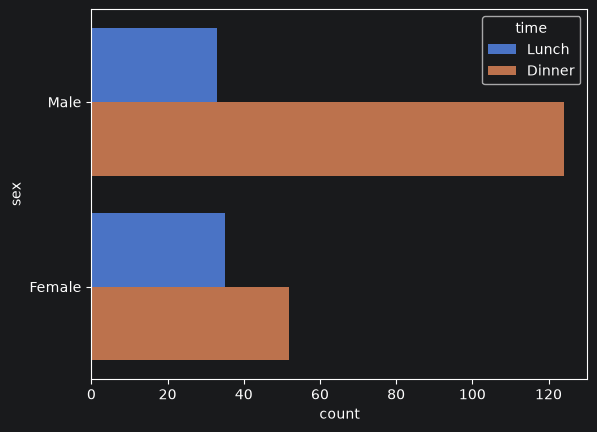

In [10]:
sns.countplot(y="sex", hue="time", data=tips)

## Verteilungen

[Distribution Plots](https://seaborn.pydata.org/tutorial/distributions.html) erlauben die Verteilung von Daten n einem Datensatz zu visualisieren:
* distplot
* jointplot
* pairplot
* rugplot
* kdeplot

### Histogramme

Ein Histogramm ist ein Balkendiagramm, bei dem die x-Achse in eine Reihe von diskreten Felder unterteilt ist und die Anzahl der jeweiligen Beobachtungen durch die Höhe des entsprechenden Balkens dargestellt wird.

**WARUM:** Verteilungen untersuchen

**WAS:** quantitative Daten

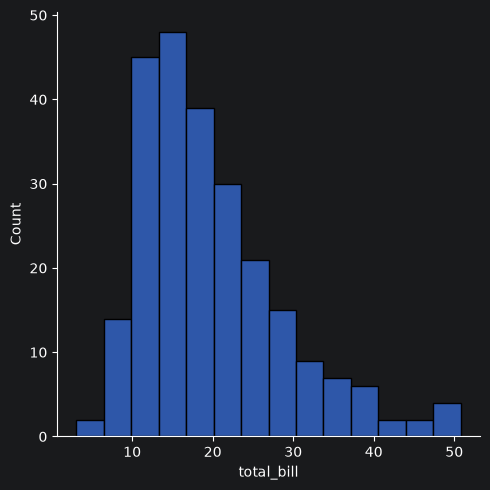

In [11]:
sns.displot(tips["total_bill"]);

Die Anzahl der Bins ist ein wichtiger Parameter und kann durch "bins" angepasst werden:

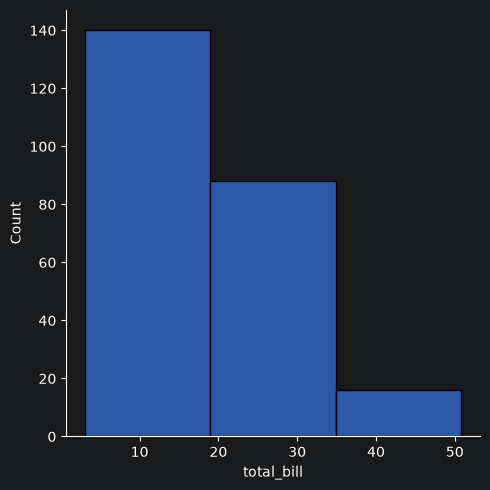

In [12]:
sns.displot(tips["total_bill"], bins=3);

Vergleich von zwei Histogramme nebeneinander - geteilt nach Male und Female:

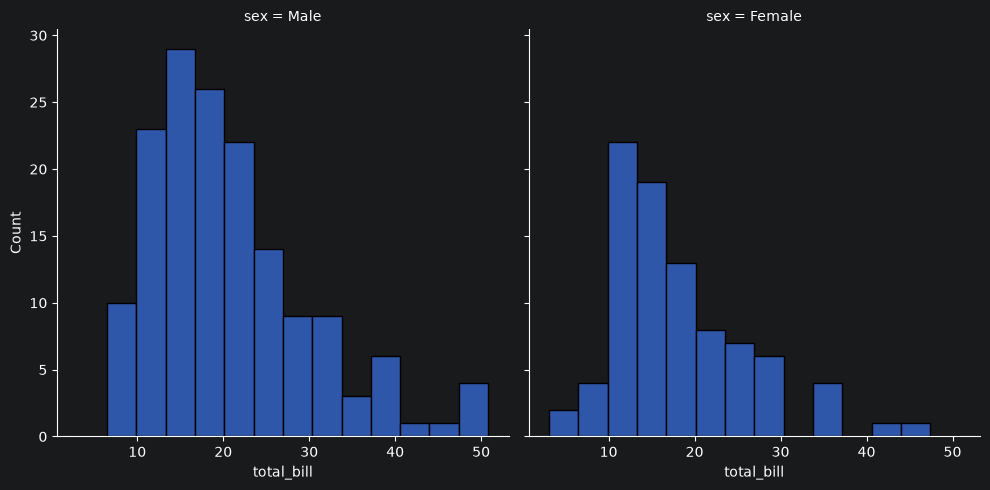

In [13]:
sns.displot(tips, x="total_bill", col="sex");


Alternativ können die Histogramme auch übereinander gelegt werden um Größen zu vergleichen:

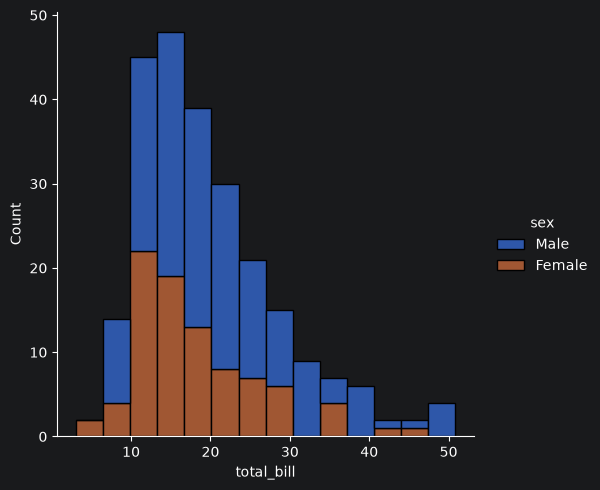

In [14]:
sns.displot(tips, x="total_bill", hue="sex", multiple="stack");

### JointPlot

Der JointPlot erlaubt die Darstellung der Verteilung zweier Variablen und deren Relation, z.B. in einem Scatterplot:

**WARUM:** Verteilungen und Relation von bivariaten Daten untersuchen

**WAS:** bivariate, quantitative Daten

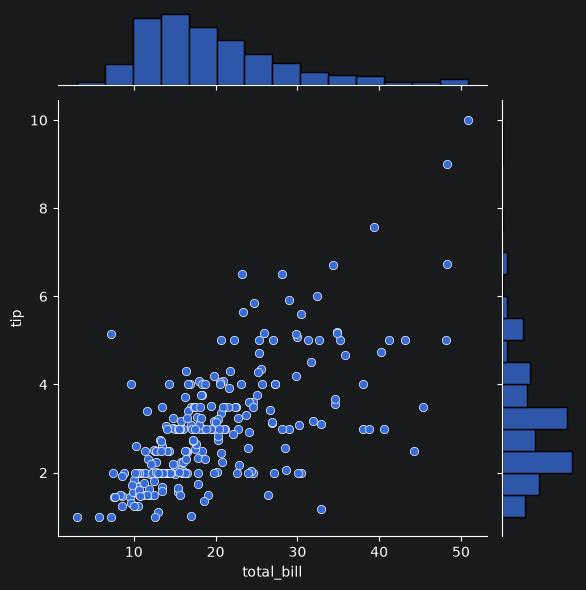

In [15]:
sns.jointplot(x="total_bill", y="tip", data=tips, kind="scatter");

Ein weiteres Beispiel ist die Nutzung von hexgonalen Bins, um Häufigkeiten in den Relationen zu untersuchen. Gerade bei vielen Datenpunkten kann es beim Scatterplot zu Überlappungen kommen, die hier besser erkannt werden können.

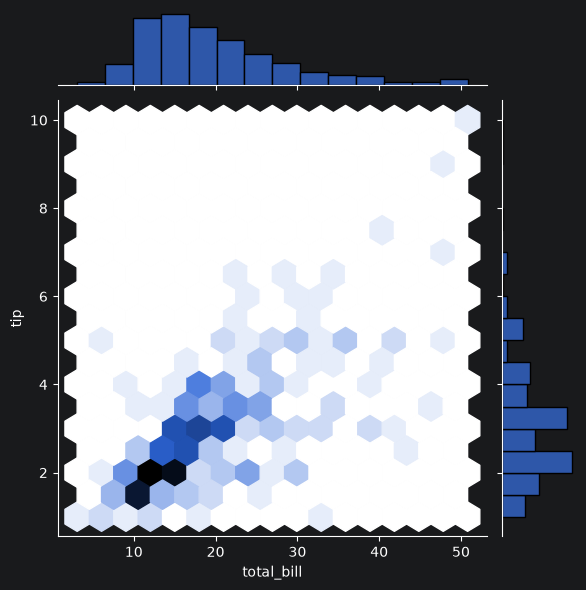

In [16]:
sns.jointplot(x="total_bill", y="tip", data=tips, kind="hex");

## Relationen

Relational Plots zeigen, wie Variablen miteinander in Beziehung stehen.

Ein wichtiges Beispiel dafür ist der **Scatterplot**, der zwei quantitative Werte gegenüberstellt.

**WARUM:** Trends, Ausreißer, Korrelationen finden, Cluster lokalisieren

**WAS:** Quantitative Werte

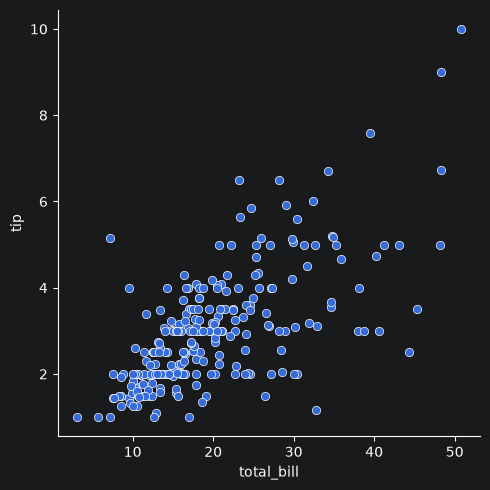

In [17]:
sns.relplot(x="total_bill", y="tip", data=tips, kind="scatter");

Weiterhin können neben der Position weitere visuelle Variablen hinzugefügt werden, z.B. die **Farbe** (in diesem Fall als ein **nominales Attribut**):

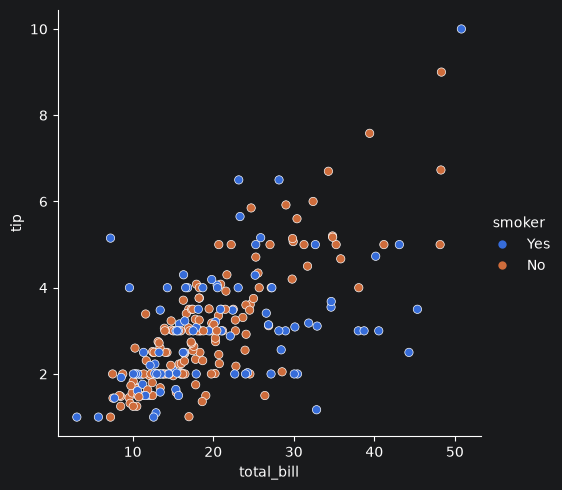

In [18]:
sns.relplot(x = "total_bill", y = "tip", hue="smoker", data = tips)

Die Farbskala passt sich automatisch an die Attributseigenschaft an. Wird ein geordnetes Attribut übergeben, wie die Größe, wird auch eine geordnete Farbskala angeboten:

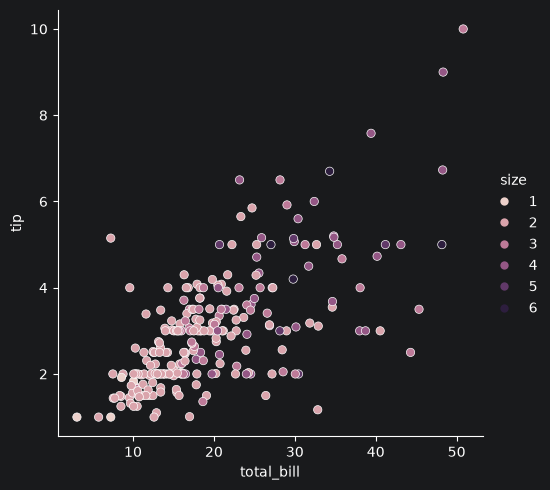

In [19]:
sns.relplot(x = "total_bill", y = "tip", hue="size", data = tips)

Weiterhin kann die **Form** und **Größe** als visuelle Variable genutzt werden um weitere Eigenschaften zu kodieren:

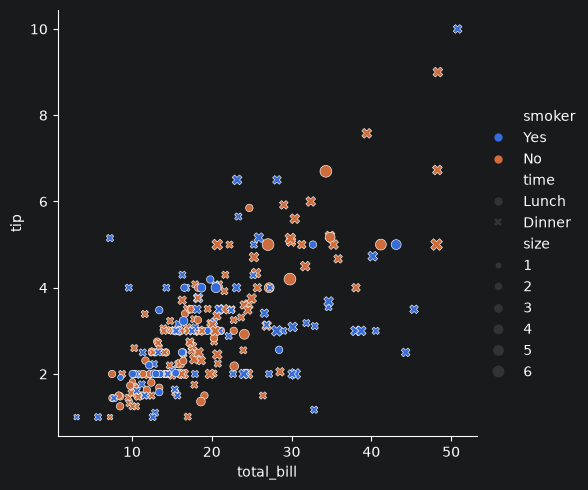

In [20]:
sns.relplot(x = "total_bill", y = "tip", hue="smoker", size="size", style="time", data = tips)

**Liniendiagramme** sind gut für die Beobachtungen von **temporalen Strukturen** geeignet. Dafür kann ebenfalls relplot mit "kind = line" genutzt werden.

**WARUM:** Trends zeigen

**WAS:** ordinale und quantitative Attribute, meist temporale Struktur

In [21]:
flights = sns.load_dataset("flights")
flights

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


Flüge von einem Monat über verschiedene Jahre vergleichen:

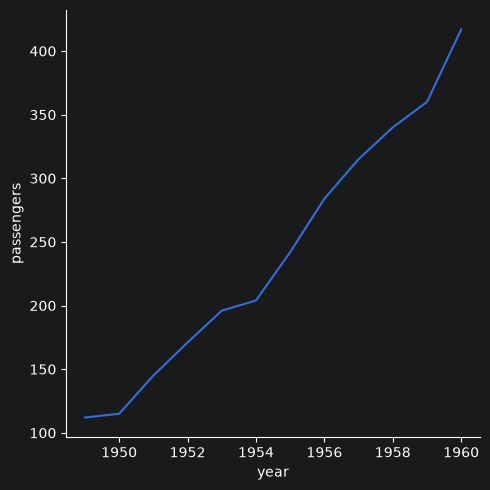

In [22]:
jan_flights = flights[(flights["month"] == "Jan")]
sns.relplot(x="year", y="passengers", kind="line", data=jan_flights);

Ebenso können mehrere Zeitverläufe verglichen werden, die z.B. durch die Farbe unterschieden werden, weiterhin kann Höhe und Breitenverhältnis festgelegt werden

Farbpaletten:
- [Matplotlib Colormaps](https://matplotlib.org/stable/tutorials/colors/colormaps.html)
- [Farbpaletten](https://seaborn.pydata.org/tutorial/color_palettes.html)
- [ColorBrewer](https://colorbrewer2.org/#type=sequential&scheme=BuGn&n=3)

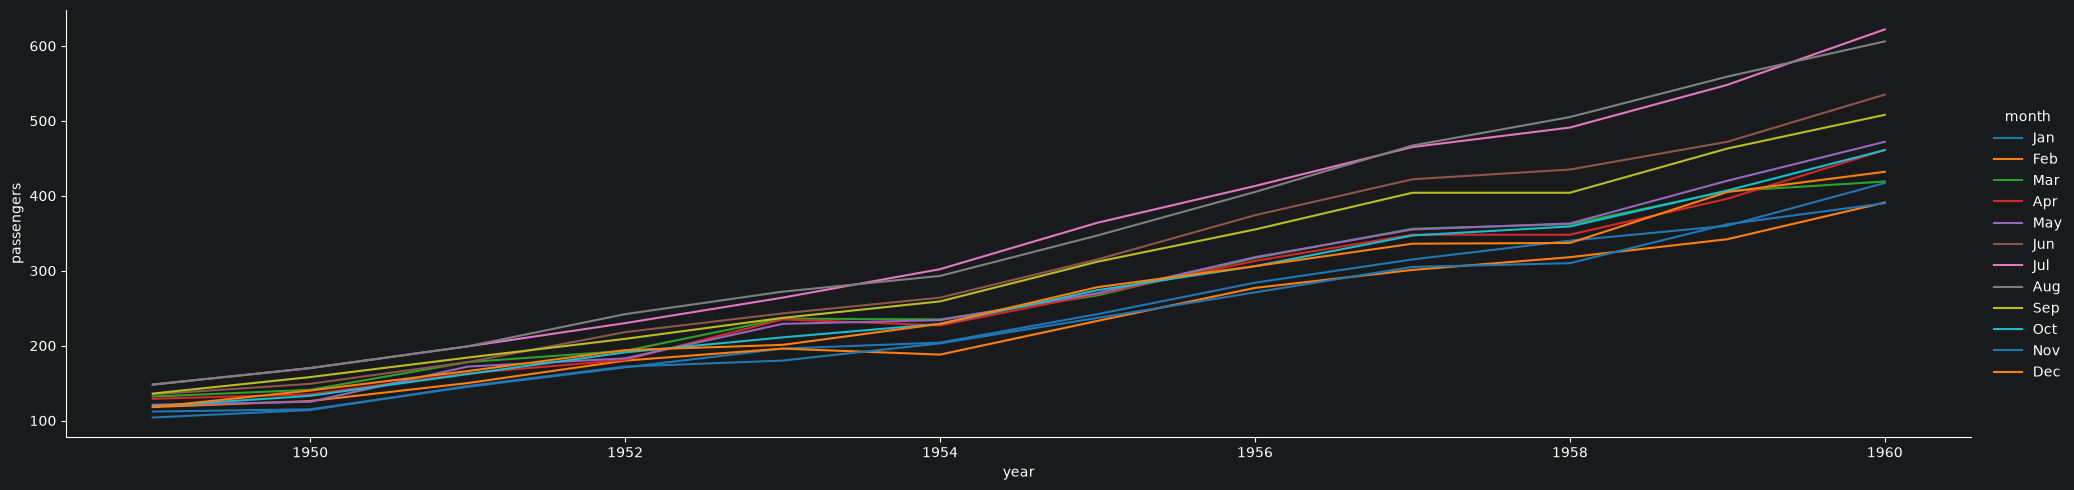

In [23]:
sns.relplot(x="year", y="passengers",
           hue="month",
           kind="line", data=flights, height = 5, aspect = 4, palette = "tab10");

## Heatmap

Eine Heatmap ist eine grafische Darstellung von Daten, bei der die einzelnen in einer Matrix enthaltenen Werte als Farben dargestellt werden.

**WARUM:** Verteilungen, Trends und Ausreißer entdecken

**WAS:** nominale oder ordinale Attribute für die Matrix, quantitative Attribute für den Farbwert

In [24]:
matrix = flights.pivot(index="month", columns="year", values="passengers")
matrix

year,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
Jan,112,115,145,171,196,204,242,284,315,340,360,417
Feb,118,126,150,180,196,188,233,277,301,318,342,391
Mar,132,141,178,193,236,235,267,317,356,362,406,419
Apr,129,135,163,181,235,227,269,313,348,348,396,461
May,121,125,172,183,229,234,270,318,355,363,420,472
Jun,135,149,178,218,243,264,315,374,422,435,472,535
Jul,148,170,199,230,264,302,364,413,465,491,548,622
Aug,148,170,199,242,272,293,347,405,467,505,559,606
Sep,136,158,184,209,237,259,312,355,404,404,463,508


<Axes: xlabel='year', ylabel='month'>

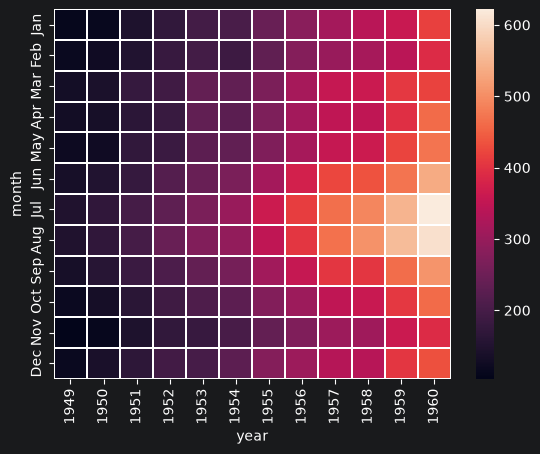

In [25]:
sns.heatmap(matrix, linewidths=0.1, cmap = "rocket") # every continuous colormap has a reversed version, which has the suffix "_r"

## Export

Visualisierung exportieren mittels ** als:
- Portable Network Graphics (PNG)
- Portable Document Format (PDF)
- Encapsulated Postscript (EPS)
- Tagged Image File Format (TIFF)
- Scalable Vector Graphics (SVG)

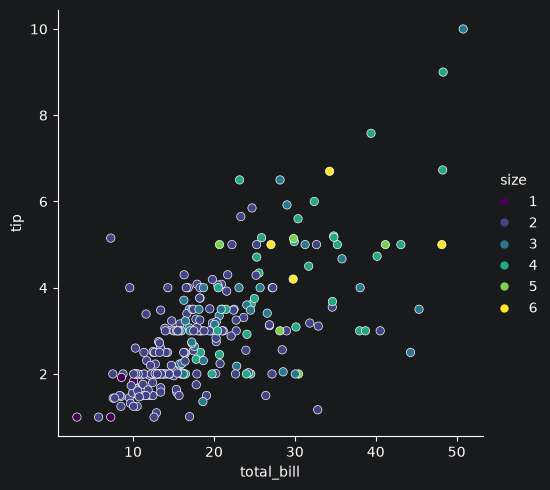

In [26]:
import matplotlib.pyplot as plt
sns.relplot(x = "total_bill", y = "tip", hue="size", data = tips, palette = "viridis")
plt.savefig('plot.pdf')